# CÀI ĐẶT THUẬT TOÁN HỒI QUY

In [1]:
import numpy as np

class LinearRegressionNumpy:
    def __init__(self):
        self.w = None
        self.b = None

    def fit(self, X, y):
        X_b = np.hstack([np.ones((len(X), 1)), X])
        beta = np.linalg.pinv(X_b.T @ X_b) @ (X_b.T @ y)
        self.b = beta[0]
        self.w = beta[1:]

    def predict(self, X):
        return X @ self.w + self.b

def evaluate_regression(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    r2 = 1.0 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
    return mse, rmse, mae, r2

# TIỀN XỬ LÝ VÀ LOẠI BỎ ĐA CỘNG TUYẾN

In [2]:
import pandas as pd

DATA_PATH = "../../Lab01/2/sp500_yahoo.csv"
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df['Return'] = df['Close'].pct_change()
df['Vol_5d'] = df['Return'].rolling(5).std()
df['MA5'] = df['Close'].rolling(5).mean()
df['MA20'] = df['Close'].rolling(20).mean()
df['Next_Close'] = df['Close'].shift(-1)
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

feature_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Return', 'MA5', 'MA20', 'Vol_5d']
X_df = df[feature_cols]
y = df['Next_Close'].values

corr = X_df.corr().abs()
drop_cols = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        col_i = corr.columns[i]
        col_j = corr.columns[j]
        if corr.iloc[i, j] > 0.98 and col_j not in drop_cols:
            drop_cols.append(col_j)

X_df_reduced = X_df.drop(columns=drop_cols)
print(f"Các cột bị loại bỏ do đa cộng tuyến (> 0.98): {drop_cols}")
print(f"Số cột ban đầu: {X_df.shape[1]} -> Số cột sau khi loại bỏ: {X_df_reduced.shape[1]}")

Các cột bị loại bỏ do đa cộng tuyến (> 0.98): ['High', 'Low', 'Close', 'MA5', 'MA20']
Số cột ban đầu: 9 -> Số cột sau khi loại bỏ: 4


# HUẤN LUYỆN VÀ SO SÁNH MÔ HÌNH

In [3]:
split_idx = int(len(X_df) * 0.8)
y_train, y_test = y[:split_idx], y[split_idx:]

X_orig = X_df.values.astype(float)
X_train_orig, X_test_orig = X_orig[:split_idx], X_orig[split_idx:]

model_orig = LinearRegressionNumpy()
model_orig.fit(X_train_orig, y_train)
y_pred_orig = model_orig.predict(X_test_orig)
mse_o, rmse_o, mae_o, r2_o = evaluate_regression(y_test, y_pred_orig)

X_red = X_df_reduced.values.astype(float)
X_train_red, X_test_red = X_red[:split_idx], X_red[split_idx:]

model_red = LinearRegressionNumpy()
model_red.fit(X_train_red, y_train)
y_pred_red = model_red.predict(X_test_red)
mse_r, rmse_r, mae_r, r2_r = evaluate_regression(y_test, y_pred_red)

print("=" * 60)
print("SO SÁNH HIỆU NĂNG (Bài 3 - Loại bỏ đa cộng tuyến):")
print(f"- Dữ liệu gốc ({X_df.shape[1]} biến)        : MSE={mse_o:.2f}, RMSE={rmse_o:.2f}, MAE={mae_o:.2f}, R2={r2_o:.4f}")
print(f"- Dữ liệu đã xử lý ({X_df_reduced.shape[1]} biến)   : MSE={mse_r:.2f}, RMSE={rmse_r:.2f}, MAE={mae_r:.2f}, R2={r2_r:.4f}")
print("=" * 60)

SO SÁNH HIỆU NĂNG (Bài 3 - Loại bỏ đa cộng tuyến):
- Dữ liệu gốc (9 biến)        : MSE=1562.35, RMSE=39.53, MAE=25.61, R2=0.9995
- Dữ liệu đã xử lý (4 biến)   : MSE=1756.11, RMSE=41.91, MAE=27.17, R2=0.9994


# VẼ ĐỒ THỊ

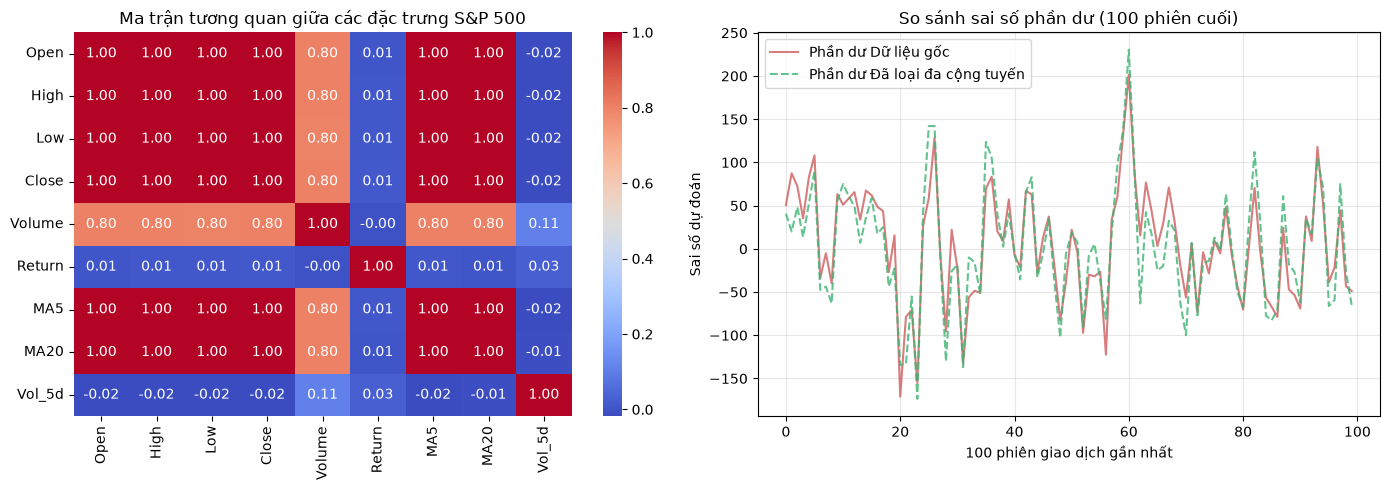

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(X_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0])
axes[0].set_title("Ma trận tương quan giữa các đặc trưng S&P 500")

axes[1].plot(y_test[-100:] - y_pred_orig[-100:], label="Phần dư Dữ liệu gốc", color="indianred", alpha=0.8)
axes[1].plot(y_test[-100:] - y_pred_red[-100:], label="Phần dư Đã loại đa cộng tuyến", color="mediumseagreen", linestyle="--", alpha=0.8)
axes[1].set_xlabel("100 phiên giao dịch gần nhất")
axes[1].set_ylabel("Sai số dự đoán")
axes[1].set_title("So sánh sai số phần dư (100 phiên cuối)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()